## Note on the .mat output from idyompy: 

Each variable corresponds to a song. For each song you have the Information Content as the first dimension, and then the Relative Entropy as the second dimension. They are both vectors over the time dimension.

This was the run from the command line to generate the analyses (after cloning IDyOMpy): `python App.py -c surprisal_analysis/sub_recordings -v pitch -k -1`


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

import pandas as pd
import seaborn as sns
import os

from statannotations.Annotator import Annotator

import sys
sys.path.append('../utils')

import warnings 
warnings.filterwarnings("ignore", category=FutureWarning)

from ERP_utils import *
from update_sub_lists import*
from plot_utils import *
from stats_utils import *

In [ ]:
def permutation_test(arr1, arr2, num_permutations=10000, alternative='two-sided', random_seed=None):
    """
    Perform a permutation test to compare the means of two distributions.
    
    arr1, arr2: 1D numpy arrays of data
    num_permutations: n permutations
    alternative: 'two-sided' (default), 'greater', 'less'
    
    returns:
    p-value of the permutation test 
    observed difference in means
    """
    if random_seed is not None:
        np.random.seed(random_seed)
        
    arr1 = np.array(arr1)
    arr2 = np.array(arr2)
    
    observed_diff = np.mean(arr1) - np.mean(arr2)
    combined = np.concatenate([arr1, arr2])
    n1 = len(arr1)
    
    count = 0
    for _ in range(num_permutations):
        np.random.shuffle(combined)
        perm_diff = np.mean(combined[:n1]) - np.mean(combined[n1:])
        
        if alternative == 'two-sided':
            if abs(perm_diff) >= abs(observed_diff):
                count += 1
        elif alternative == 'greater':
            if perm_diff >= observed_diff:
                count += 1
        elif alternative == 'less':
            if perm_diff <= observed_diff:
                count += 1
        else:
            raise ValueError("alternative must be 'two-sided', 'greater' or 'less'")
    
    p_value = (count + 1) / (num_permutations + 1) 
    
    return p_value, observed_diff

def cohen_d(arr1, arr2):
    """
    Calculate Cohen's d effect size between two arrays
    arr1, arr2: numpy arrays or lists of numeric data
    """
    arr1 = np.array(arr1)
    arr2 = np.array(arr2)
    
    mean1 = np.mean(arr1)
    mean2 = np.mean(arr2)
    std1 = np.std(arr1, ddof=1)
    std2 = np.std(arr2, ddof=1)
    
    n1 = len(arr1)
    n2 = len(arr2)
    
    pooled_std = np.sqrt(((n1 - 1)*std1**2 + (n2 - 1)*std2**2) / (n1 + n2 - 2))
    
    d = (mean1 - mean2) / pooled_std
    
    return d


In [3]:
#surprisal data from idyom
surprisal_data = loadmat('../data_idyom/likelihoods_cross-eval_k_fold_-1_quantization_24_maxOrder_20_viewpoints_pitch.mat')
keystroke_path = '../data_idyom/keystroke_data'

#load keystrokes to find the firsts and others 
subjects_to_process = ['13','14','15','16','17','18','19','20'] #subs whose recordings were used in listening
keystroke_df = pd.DataFrame()
for sub in subjects_to_process:
    keystroke_df_sub = pd.read_csv(os.path.join(keystroke_path, f'keystrokes_{sub}_pre.csv'))
    surprisal_sub = surprisal_data[f'audio_{sub}_pre'][0]
    keystroke_df_sub['surprisal'] = surprisal_sub
    keystroke_df_sub['subject'] = sub
    keystroke_df = pd.concat([keystroke_df, keystroke_df_sub], ignore_index=True)

#make shuffled labels for permutation test
keystroke_df['epochtype_shuf'] = np.random.permutation(keystroke_df['epochtype'].values)

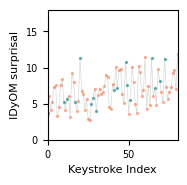

In [ ]:
#plot example melody over time
sub = '13'
keystrokes_f = keystroke_df.query('subject == @sub and epochtype == "first"')
keystrokes_o = keystroke_df.query('subject == @sub and epochtype == "other"')

keystrokes_all = pd.concat([keystrokes_f, keystrokes_o]).sort_index()

fig = plt.figure(figsize=(1.3, 1.3))
ax = fig.add_axes([0,0,1,1])

plt.plot(keystrokes_all.index, keystrokes_all['surprisal'].values, color='gray', alpha=0.3, linewidth = 0.5)
plt.scatter(keystrokes_f.index, keystrokes_f['surprisal'].values, color='teal', alpha=0.5, s=2)
plt.scatter(keystrokes_o.index, keystrokes_o['surprisal'].values, color='coral', alpha=0.5, s=2)

plt.xlabel('Keystroke Index', fontsize=8)
plt.ylabel('IDyOM surprisal', fontsize=8)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.ylim(0, 18)
plt.xlim(0, 80)
plt.savefig(f'./figures/keystroke_surprisal_{sub}.svg', transparent=True)


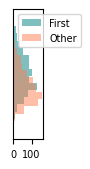

In [ ]:
#plot histogram with size-matched samples
fig = plt.figure(figsize = (0.3,1.3))
ax = fig.add_axes([0,0,1,1])

n_firsts = keystroke_df.query('epochtype == "first"')['surprisal'].values.shape

plt.hist(keystroke_df.query('epochtype == "first"')['surprisal'].values, bins=50, alpha=0.5, label='First', color='teal', orientation = 'horizontal')
plt.hist(np.random.choice(keystroke_df.query('epochtype == "other"')['surprisal'].values, n_firsts), bins=50, alpha=0.5, label='Other', color='coral', orientation = 'horizontal')
plt.ylim(0,18)

plt.xticks(fontsize = 7)
# plt.yticks(fontsize = 7)
plt.legend(fontsize = 9)




# plt.xticks([])
plt.yticks([])
plt.legend(fontsize = 7)
plt.savefig(f'./figures/keystroke_surprisal_hist_{sub}.svg')

In [ ]:
sub = '18'
n_samp = 100
n_bins = 25
n_iter = 1000

stats_list = []

for sub in subjects_to_process:
    diffs = []
    cohens = []

    for _ in range(n_iter):
        #sample n_samp surprisals for "other" and "first" epochs
        others_sub = np.random.choice(
            keystroke_df.query(f'subject == "{sub}" and epochtype == "other"')['surprisal'].values,
            size=n_samp, replace=True
        )
        firsts_sub = np.random.choice(
            keystroke_df.query(f'subject == "{sub}" and epochtype == "first"')['surprisal'].values,
            size=n_samp, replace=True
        )

        #compute mean difference
        diff_iter = np.mean(firsts_sub) - np.mean(others_sub)
        diffs.append(diff_iter)

        #compute Cohens d
        cohens_sub = cohen_d(firsts_sub, others_sub)
        cohens.append(cohens_sub)

    stats_list.append({
        'subject':     sub,
        'bs_diff_mean': np.mean(diffs),
        'bs_diff_se':   np.std(diffs, ddof=1),
        'bs_cohen_mean': np.mean(cohens),
        'bs_cohen_ci_lower': np.percentile(cohens, 2.5),
        'bs_cohen_ci_upper': np.percentile(cohens, 97.5),
        'bs_diff_dist': diffs,
        'bs_cohen_dist': cohens
    })

stats_df = pd.DataFrame(stats_list)

In [8]:
cohen_d(firsts_sub, others_sub)

0.13415698818879368

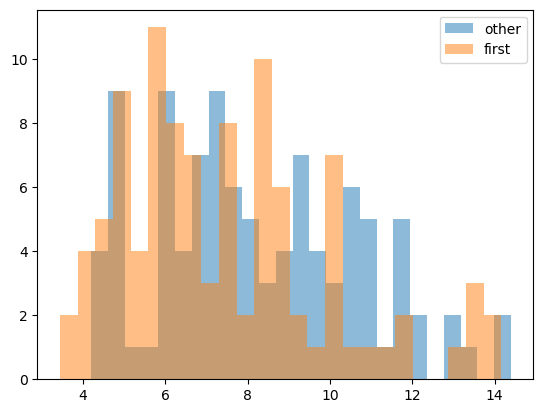

In [9]:
# plt.hist(keystroke_df.query('epochtype_shuf == "first"')['surprisal'], bins = 50, alpha=0.5, label='first')
sub = '14'
n_samp = 100
n_bins = 25


others_sub = np.random.choice(keystroke_df.query(f'subject == "{sub}" and epochtype == "other"')['surprisal'].values, n_samp)
firsts_sub = np.random.choice(keystroke_df.query(f'subject == "{sub}" and epochtype == "first"')['surprisal'].values, n_samp)
plt.hist(firsts_sub, bins = n_bins, alpha=0.5, label='other')
plt.hist(others_sub, bins = n_bins, alpha=0.5, label='first')

plt.legend()

## Compare firsts and others bootstrap

In [ ]:
def bootstrap_diffs_surprisal(df, cond1, cond2, n_iter=200, n_samp=100):
    """
    df: dataframe with columns
        - subject
        - epochtype ('firsts' / 'other')
        - epochs (or similar array-like per row)

    Returns:
        array: (n_iter, n_subjects) mean differences at selected timepoint
    """

    subjects = df['subject'].unique()
    boot_all = []

    for i in range(n_iter):
        subj_diffs = []

        for s in subjects:
            df_s = df[df['subject'] == s]

            firsts = df_s[df_s['epochtype'] == cond1]
            others = df_s[df_s['epochtype'] == cond2]
            # skip subjects with insufficient data
            if len(firsts) < n_samp or len(others) < n_samp:
                continue

            firsts_samp = firsts.sample(n_samp, replace=True)
            others_samp = others.sample(n_samp, replace=True)

            firsts_ev = np.mean(np.stack(firsts_samp['surprisal'].values), axis=0)
            others_ev = np.mean(np.stack(others_samp['surprisal'].values), axis=0)

            diff = firsts_ev - others_ev

            # extract channels at timepoint
            subj_diffs.append(diff)

        boot_all.append(np.mean(subj_diffs, axis=0))

    return np.stack(boot_all)

In [48]:
bs_distr = bootstrap_diffs_surprisal(keystroke_df, cond1= 'first',cond2= 'other')
bs_distr_null = bootstrap_diffs_surprisal(keystroke_df, cond1= 'other', cond2='other')

ci_l_listen, ci_u_listen = ci95_bs(bs_distr, axis = 0)


Text(0.5, 1.0, 'first vs others bootstrap (idyompy surprisal values)')

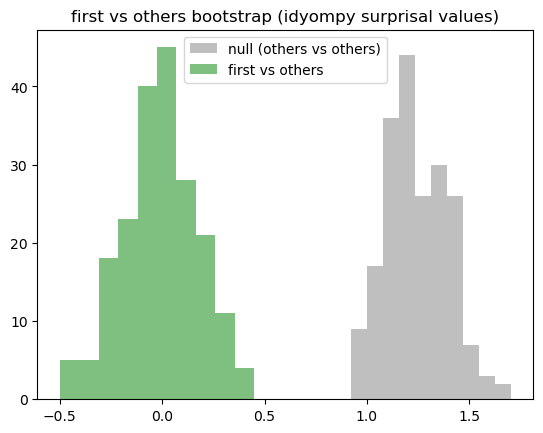

In [54]:
plt.hist(bs_distr, alpha = 0.5, color = 'gray', label = 'null (others vs others)')
plt.hist(bs_distr_null, color = 'green', alpha = 0.5,  label = 'first vs others')
plt.legend()
plt.title('first vs others bootstrap (idyompy surprisal values)')

/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/anaconda3/envs/am-eeg/lib/python3.12/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

14_first vs. 14_other: Mann-Whitney-Wilcoxon test two-sided, P_val:1.731e-07 U_stat=3.709e+04
13_first vs. 13_other: Mann-Whitney-Wilcoxon test two-sided, P_val:3.140e-07 U_stat=3.012e+04
15_first vs. 15_other: Mann-Whitney-Wilcoxon test two-sided, P_val:3.206e-04 U_stat=2.445e+04
16_first vs. 16_other: Mann-Whitney-Wilcoxon test two-sided, P_val:7.396e-10 U_stat=2.320e+04
17_first vs. 17_other: Mann-Whitney-Wilcoxon test two-sided, P_val:2.234e-03 U_stat=1.977e+04
18_first vs. 18_other: Mann-Whitney-Wilcoxon test two-sided, P_val:8.210e-16 U_stat=3.684e+04
19_first vs. 19_other: Mann-Whitney-Wilcoxon test two-sided, P_val:6.770e-08 U_stat=4.559e+04
20_first vs. 20_other: Mann-Whitney-Wilcoxon test two-sided, P_val:2.906e-02 U_stat=1.604e+04


(<Axes: xlabel='subject', ylabel='surprisal'>,
  <statannotations.Annotation.Annotation at 0x15c854890>])

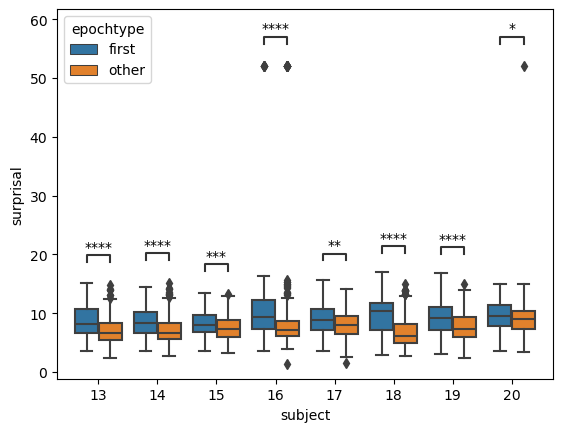

In [10]:
ax = sns.boxplot(data = keystroke_df, x = 'subject', y = 'surprisal', hue='epochtype')

pairs = [(('13', 'first'), ('13', 'other')),
         (('14', 'first'), ('14', 'other')),
         (('15', 'first'), ('15', 'other')),
         (('16', 'first'), ('16', 'other')),
         (('17', 'first'), ('17', 'other')),
         (('18', 'first'), ('18', 'other')),
         (('19', 'first'), ('19', 'other')),
         (('20', 'first'), ('20', 'other'))]
annotator = Annotator(ax, pairs=pairs, data=keystroke_df, x='subject', y='surprisal', hue='epochtype')

annotator.configure(test = 'Mann-Whitney')
annotator.apply_and_annotate()